Dataset shape: (150, 2)


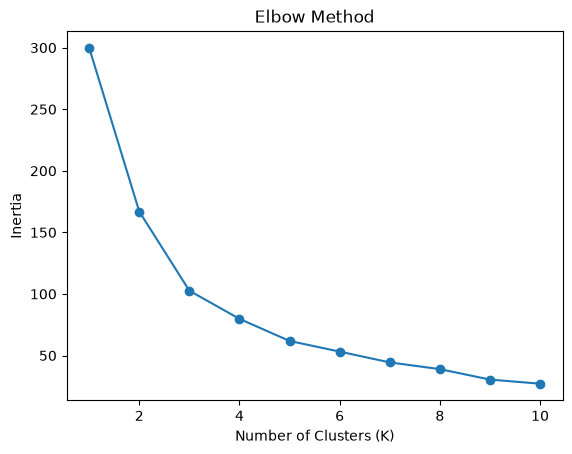

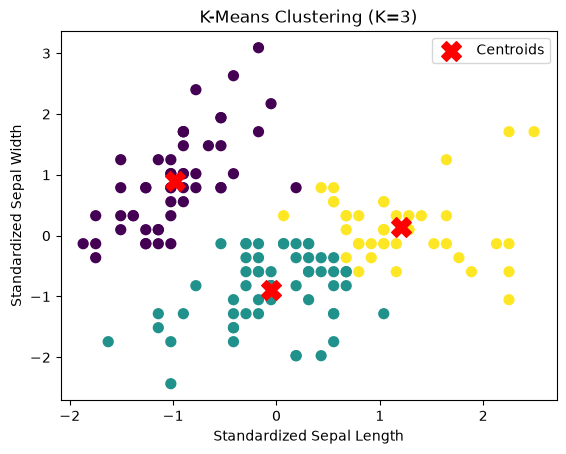


First 10 cluster assignments:
[0 0 0 0 0 0 0 0 0 0]


In [5]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

iris=load_iris()
X=iris.data[:,:2]
print("Dataset shape:",X.shape)

scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

inertia=[]
for k in range(1,11):
    model=KMeans(n_clusters=k,random_state=42,n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.plot(range(1,11),inertia,marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

kmeans=KMeans(n_clusters=3,random_state=42,n_init=10)
clusters=kmeans.fit_predict(X_scaled)

plt.scatter(X_scaled[:,0],X_scaled[:,1],c=clusters,cmap='viridis',s=50)
plt.scatter(kmeans.cluster_centers_[:,0],kmeans.cluster_centers_[:,1],marker='X',s=200,color='red',label='Centroids')
plt.xlabel("Standardized Sepal Length")
plt.ylabel("Standardized Sepal Width")
plt.title("K-Means Clustering (K=3)")
plt.legend()
plt.show()

print("\nFirst 10 cluster assignments:")
print(clusters[:10])